In [1]:
import os
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

print("TensorFlow version:", tf.__version__)
print("Libraries imported successfully!")

TensorFlow version: 2.21.0
Libraries imported successfully!


In [2]:
save_path = Path(
    r"C:\Users\ABHAY YADAV\OneDrive\Desktop\ghub\plan leaf disease system\prepared_data.pkl"
)

with open(save_path, "rb") as file:
    prepared_data = pickle.load(file)

train_df = prepared_data["train_df"]
val_df = prepared_data["val_df"]
test_df = prepared_data["test_df"]
class_names = prepared_data["class_names"]

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))
print("Classes:", class_names)

Training images: 5305
Validation images: 1137
Testing images: 1137
Classes: ['Tomato___healthy', 'Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold']


In [3]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 16
SEED = 42

class_to_index = {
    name: index for index, name in enumerate(class_names)
}

print("MobileNetV2 configuration ready!")

MobileNetV2 configuration ready!


In [4]:
def load_mobilenet_image(image_path, label):

    image = tf.io.read_file(image_path)

    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(image, IMG_SIZE)

    # MobileNetV2 preprocessing
    image = preprocess_input(image)

    return image, label

In [5]:
def create_mobilenet_dataset(dataframe, shuffle=False):

    image_paths = dataframe["image_path"].values

    labels = dataframe["label"].map(class_to_index).values

    dataset = tf.data.Dataset.from_tensor_slices(
        (image_paths, labels)
    )

    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=SEED
        )

    dataset = dataset.map(
        load_mobilenet_image,
        num_parallel_calls=2
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(1)

    return dataset

In [6]:
train_dataset = create_mobilenet_dataset(train_df, shuffle=True)
val_dataset = create_mobilenet_dataset(val_df)
test_dataset = create_mobilenet_dataset(test_df)

print("MobileNetV2 datasets created successfully!")

MobileNetV2 datasets created successfully!


In [7]:
for images, labels in train_dataset.take(1):

    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())

Image batch shape: (16, 224, 224, 3)
Label batch shape: (16,)
Minimum pixel value: -1.0
Maximum pixel value: 0.93401563


In [8]:
base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

print("MobileNetV2 loaded successfully!")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
MobileNetV2 loaded successfully!


In [9]:
base_model.trainable = False

print("Pretrained MobileNetV2 layers frozen.")
print("Total layers:", len(base_model.layers))

Pretrained MobileNetV2 layers frozen.
Total layers: 154


In [10]:
mobilenet_model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    base_model,

    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation="relu"),

    layers.Dropout(0.4),

    layers.Dense(len(class_names), activation="softmax")
])

mobilenet_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224 (Functional)    │ (None, 7, 7, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         163,968 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 5)                   │             645 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,422,597 (9.24 MB)

 Trainable params: 164,613 (643.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [11]:
mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("MobileNetV2 model compiled successfully!")

MobileNetV2 model compiled successfully!


In [12]:
EPOCHS = 10

print("Epochs:", EPOCHS)
print("Batch size:", BATCH_SIZE)

Epochs: 10
Batch size: 16


In [13]:
history_mobilenet = mobilenet_model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS
)

Epoch 1/10
332/332 ━━━━━━━━━━━━━━━━━━━━ 99s 280ms/step - accuracy: 0.6801 - loss: 0.8861 - val_accuracy: 0.8734 - val_loss: 0.4563
Epoch 2/10
332/332 ━━━━━━━━━━━━━━━━━━━━ 142s 282ms/step - accuracy: 0.8490 - loss: 0.4519 - val_accuracy: 0.8945 - val_loss: 0.3227
Epoch 3/10
332/332 ━━━━━━━━━━━━━━━━━━━━ 88s 266ms/step - accuracy: 0.8865 - loss: 0.3415 - val_accuracy: 0.9164 - val_loss: 0.2697
Epoch 4/10
332/332 ━━━━━━━━━━━━━━━━━━━━ 88s 265ms/step - accuracy: 0.9050 - loss: 0.2858 - val_accuracy: 0.9208 - val_loss: 0.2401
Epoch 5/10
332/332 ━━━━━━━━━━━━━━━━━━━━ 88s 264ms/step - accuracy: 0.9203 - loss: 0.2427 - val_accuracy: 0.9270 - val_loss: 0.2155
Epoch 6/10
332/332 ━━━━━━━━━━━━━━━━━━━━ 88s 265ms/step - accuracy: 0.9320 - loss: 0.2123 - val_accuracy: 0.9314 - val_loss: 0.2042
Epoch 7/10
332/332 ━━━━━━━━━━━━━━━━━━━━ 88s 264ms/step - accuracy: 0.9412 - loss: 0.1928 - val_accuracy: 0.9393 - val_loss: 0.1873
Epoch 8/10
332/332 ━━━━━━━━━━━━━━━━━━━━ 88s 266ms/step - accuracy: 0.9448 - loss: 

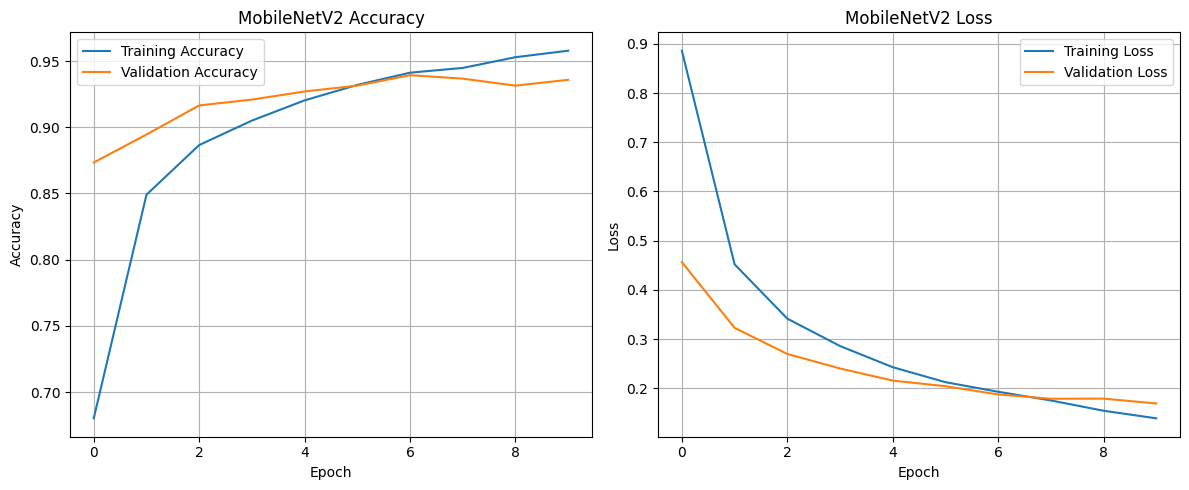

In [14]:
plt.figure(figsize=(12, 5))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history_mobilenet.history["accuracy"], label="Training Accuracy")
plt.plot(history_mobilenet.history["val_accuracy"], label="Validation Accuracy")
plt.title("MobileNetV2 Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# Loss
plt.subplot(1, 2, 2)
plt.plot(history_mobilenet.history["loss"], label="Training Loss")
plt.plot(history_mobilenet.history["val_loss"], label="Validation Loss")
plt.title("MobileNetV2 Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [15]:
os.makedirs("models", exist_ok=True)

mobilenet_model.save("models/mobilenetv2.keras")

print("MobileNetV2 model saved successfully!")

MobileNetV2 model saved successfully!


In [16]:
test_loss_mobilenet, test_accuracy_mobilenet = mobilenet_model.evaluate(
    test_dataset
)

print("MobileNetV2 Test Loss:", round(test_loss_mobilenet, 4))
print(
    "MobileNetV2 Test Accuracy:",
    round(test_accuracy_mobilenet * 100, 2), "%"
)

72/72 ━━━━━━━━━━━━━━━━━━━━ 17s 233ms/step - accuracy: 0.9464 - loss: 0.1471
MobileNetV2 Test Loss: 0.1471
MobileNetV2 Test Accuracy: 94.64 %


In [17]:
y_true_mobilenet = []
y_pred_mobilenet = []

for images, labels in test_dataset:
    predictions = mobilenet_model.predict(images, verbose=0)

    predicted_classes = np.argmax(predictions, axis=1)

    y_true_mobilenet.extend(labels.numpy())
    y_pred_mobilenet.extend(predicted_classes)

print("MobileNetV2 predictions generated!")

MobileNetV2 predictions generated!


In [18]:
from sklearn.metrics import classification_report

print(classification_report(
    y_true_mobilenet,
    y_pred_mobilenet,
    target_names=class_names
))

                         precision    recall  f1-score   support

       Tomato___healthy       0.98      1.00      0.99       238
Tomato___Bacterial_spot       0.94      0.98      0.96       319
  Tomato___Early_blight       0.90      0.80      0.85       150
   Tomato___Late_blight       0.94      0.94      0.94       287
     Tomato___Leaf_Mold       0.95      0.94      0.95       143

               accuracy                           0.95      1137
              macro avg       0.94      0.93      0.94      1137
           weighted avg       0.95      0.95      0.95      1137



In [19]:
import pandas as pd

comparison = pd.DataFrame({
    "Model": ["Custom CNN", "MobileNetV2"],
    "Test Accuracy": [0.93, 0.95],
    "Approach": [
        "Custom CNN from scratch",
        "Transfer Learning"
    ]
})

comparison

,Model,Test Accuracy,Approach
0,Custom CNN,0.93,Custom CNN from scratch
1,MobileNetV2,0.95,Transfer Learning


In [20]:
from pathlib import Path

model_path = Path("models/mobilenetv2.keras")

print("Model exists:", model_path.exists())
print("Model path:", model_path.resolve())

Model exists: True
Model path: C:\Users\ABHAY YADAV\models\mobilenetv2.keras


In [21]:
import shutil
from pathlib import Path

source = Path(r"C:\Users\ABHAY YADAV\models\mobilenetv2.keras")

destination_folder = Path(
    r"C:\Users\ABHAY YADAV\OneDrive\Desktop\ghub\plan leaf disease system\models"
)

destination_folder.mkdir(parents=True, exist_ok=True)

destination = destination_folder / "mobilenetv2.keras"

shutil.copy2(source, destination)

print("Model copied:", destination.exists())
print("New location:", destination)

Model copied: True
New location: C:\Users\ABHAY YADAV\OneDrive\Desktop\ghub\plan leaf disease system\models\mobilenetv2.keras
